In [54]:
from collections import defaultdict
from pathlib import Path

import pandas as pd
import h3pandas
import numpy as np
from tqdm.auto import tqdm

In [13]:
def clean_dataset(data):
    num_obs = len(data)
    data = data[
        (
            (data["latitude"] <= 90)
            & (data["latitude"] >= -90)
            & (data["longitude"] <= 180)
            & (data["longitude"] >= -180)
        )
    ]
    if (num_obs - len(data)) > 0:
        print(f"  {num_obs - len(data)} items filtered due to invalid locs")

    num_obs = len(data)
    data = data.dropna()
    if (num_obs - len(data)) > 0:
        print(f"  {num_obs - len(data)} items filtered due to NaN entry")

    print(f"  after cleaning, we have {len(data)} records.")
    return data

In [33]:
def load_inat_dataset_from_parquet(spatial_data_file):
    print("inat style dataset")
    print(" reading parquet")
    spatial_data = pd.read_parquet(
        spatial_data_file,
        columns=[
            "leaf_class_id",
            "latitude",
            "longitude",
            "taxon_id",
            "spatial_class_id",
        ],
    )
    spatial_data = spatial_data.dropna(subset="leaf_class_id")
    print(" cleaning dataset")
    spatial_data = clean_dataset(spatial_data)
    print(" shuffling")
    spatial_data = spatial_data.sample(frac=1)
    print(" extracting locs")
    locs = np.vstack(
        (spatial_data["longitude"].values, spatial_data["latitude"].values)
    ).T.astype(np.float32)

    print(" extracting taxon_id")
    taxon_ids = spatial_data["taxon_id"].values.astype(int)
    unique_taxa, _ = np.unique(taxon_ids, return_inverse=True)

    print(" extracting spatial class ids")
    class_ids = spatial_data["spatial_class_id"].values.astype(int)
    print(f" found {len(unique_taxa)} unique taxa")

    print(" doing h3 conversion")
    spatial_data_h3 = spatial_data.h3.geo_to_h3(
        5,
        lat_col="latitude",
        lng_col="longitude",
    )
    spatial_data_h3.reset_index(inplace=True)  
    h3_idx = spatial_data_h3["h3_05"].values
    
    return locs, class_ids, unique_taxa, h3_idx


In [34]:
inat_2_17_export = Path("/data-ssd/alex/datasets/vision-export-20240929050006-aka-2.17")
inat_2_17_data = inat_2_17_export / "spatial_data.parquet"
(locs, class_ids, unique_taxa, h3_idx) = load_inat_dataset_from_parquet(inat_2_17_data)

inat style dataset
 reading parquet
 cleaning dataset
  12 items filtered due to invalid locs
  after cleaning, we have 161065443 records.
 shuffling
 extracting locs
 extracting taxon_id
 extracting spatial class ids
 found 95903 unique taxa
 doing h3 conversion


In [84]:
tax = pd.read_csv(inat_2_17_export / "taxonomy.csv")

In [69]:
def _get_idx_subsample_observations_h3(labels, h3_idx, hard_cap=-1):
    if hard_cap == -1:
        return np.arange(len(labels))

    print(f"  subsampling (up to) {hard_cap} per class for the training set")
    class_counts = {id: 0 for id in np.unique(labels)}
    cells_dict = defaultdict(list)
    
    ss_rng = np.random.default_rng()
    idx_rand = ss_rng.permutation(len(labels))
    idx_ss = []
    for i in tqdm(idx_rand):
        class_id = labels[i]
        h3_cell = h3_idx[i]
        if class_counts[class_id] < hard_cap:
            if class_id not in cells_dict[h3_cell]:
                idx_ss.append(i)
                class_counts[class_id] += 1
                cells_dict[h3_cell].append(class_id)
    idx_ss = np.sort(idx_ss)
    print(f"  final training set size: {len(idx_ss)}")
    return idx_ss


In [91]:
ss_idx_hd = _get_idx_subsample_observations_h3(class_ids, h3_idx, hard_cap=1_000)

  subsampling (up to) 1000 per class for the training set


  0%|          | 0/161065443 [00:00<?, ?it/s]

  final training set size: 23182994


In [95]:
class_ids_h3_ss = np.array(class_ids)[ss_idx_hd]
pd.Series(class_ids_h3_ss).value_counts()

77881    1000
88877    1000
10162    1000
83739    1000
39010    1000
         ... 
73625       1
40141       1
9181        1
21782       1
83502       1
Name: count, Length: 95903, dtype: int64

In [96]:
def _get_idx_subsample_observations(labels, hard_cap=-1):
    if hard_cap == -1:
        return np.arange(len(labels))

    print(f"  subsampling (up to) {hard_cap} per class for the training set")
    class_counts = {id: 0 for id in np.unique(labels)}
    ss_rng = np.random.default_rng()
    idx_rand = ss_rng.permutation(len(labels))
    idx_ss = []
    for i in tqdm(idx_rand):
        class_id = labels[i]
        if class_counts[class_id] < hard_cap:
            idx_ss.append(i)
            class_counts[class_id] += 1
    idx_ss = np.sort(idx_ss)
    print(f"  final training set size: {len(idx_ss)}")
    return idx_ss


In [97]:
ss_idx = _get_idx_subsample_observations(class_ids, hard_cap=1_000)

  subsampling (up to) 1000 per class for the training set


  0%|          | 0/161065443 [00:00<?, ?it/s]

  final training set size: 43809253


In [98]:
class_ids_ss = np.array(class_ids)[ss_idx]
pd.Series(class_ids_ss).value_counts()

20103    1000
52638    1000
6403     1000
63975    1000
60522    1000
         ... 
92374      42
5260       40
66530      36
40141      33
45216      18
Name: count, Length: 95903, dtype: int64

In [108]:
df = pd.DataFrame({
    "discretized sampling": pd.Series(class_ids_h3_ss).value_counts(),
    "flat sampling": pd.Series(class_ids_ss).value_counts(),
})

Text(0, 0.5, 'Count of unique taxa')

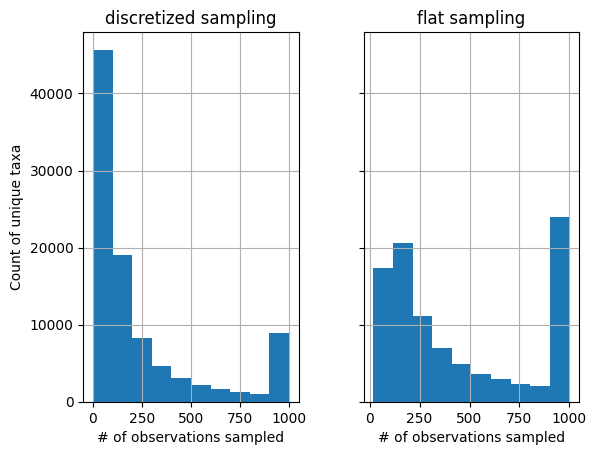

In [131]:
ax = df.hist(sharey=True)
ax[0][0].set_xlabel("# of observations sampled")
ax[0][1].set_xlabel("# of observations sampled")
ax[0][0].set_ylabel("Count of unique taxa")

In [89]:
tax[tax.leaf_class_id==78375]

,parent_taxon_id,taxon_id,rank_level,leaf_class_id,iconic_class_id,spatial_class_id,name
354,740.0,94499,10.0,78375.0,5.0,78375,Arborophila campbelli


In [90]:
spatial_data[spatial_data.leaf_class_id==78375]

,leaf_class_id,latitude,longitude,taxon_id,spatial_class_id
141661017,78375.0,3.7120,101.7363,94499,78375
141661014,78375.0,3.7118,101.7413,94499,78375
141661085,78375.0,3.7119,101.7366,94499,78375
141661080,78375.0,3.7121,101.7414,94499,78375
141661056,78375.0,3.7047,101.7432,94499,78375
...,...,...,...,...,...
141661033,78375.0,3.7119,101.7366,94499,78375
141661067,78375.0,3.7119,101.7366,94499,78375
141661020,78375.0,3.7115,101.7377,94499,78375
141661035,78375.0,3.7119,101.7366,94499,78375


```
 25 sampling:
 26     discretized_sampling: True
 27     h3_resolution: 5
```

```
 90         ds, num_train_steps_per_epoch = make_subsampled_dataset_h3(
 91             config["hard_cap"],
 92             encoded_locs,
 93             class_ids,
 94             config["batch_size"],
 95             config["shuffle_buffer_size"],
 96             config["sampling"]["h3_resolution"]
 97         )
```

```
 55     if config["sampling"]["discretized_sampling"]:
 56         (locs, class_ids, unique_taxa, h3_idx) = load_sinr_dataset_from_parquet_h3(
 57             config["sinr_dataset"]["train_data"],
 58             h3_resolution=config["sampling"]["h3_resolution"]
 59         )
```